# Testing Logistic Regression (Model B) & Kernel SVM (Model B_2)

Notebook thử nghiệm và đối chiếu hai mô hình của nhánh `Dat-2`:
- **Model B**: Logistic Regression (`src/model_b.py`, đánh giá qua `src/metric_model_b.py`, `class_weight="balanced"`).
- **Model B_2**: Kernel SVM - RBF (`src/model_b_2.py`, xử lý mất cân bằng bằng `RandomUnderSampler(0.05)`, chuẩn hóa `StandardScaler`, hiệu chỉnh xác suất Platt Scaling qua `CalibratedClassifierCV`, đánh giá qua `src/metric_model_b_2.py`).

**Nội dung thực nghiệm:**
1. Chạy trực tiếp 2 pipeline chuẩn `run_model_b()` và `run_model_b_2()`.
2. Thử nghiệm ablation trên 3 biến thể đặc trưng thời gian (`data_no_hour`, `data_sincos`, `data_hour`) tương tự `Ensemble+ANN_testing.ipynb`.
3. Tổng hợp bảng so sánh (ở ngưỡng mặc định `t = 0.50` và ngưỡng tối ưu F1 tìm trên Out-Of-Fold CV) kèm biểu đồ trực quan.

In [1]:
import os
import sys
import time
from pathlib import Path

if not Path("src").exists() and Path("../src").exists():
    os.chdir("..")
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import precision_recall_curve

from src.config import RAW_DATA_PATH, RANDOM_STATE, TEST_SIZE, COLS_TO_SCALE, FIGURE_DIR
from src.preprocess import load_and_clean_data, split_train_test, get_cv_splitter
from src.model_b import (
    run_model_b,
    build_model as build_lr_model,
    handle_imbalance as handle_imbalance_lr,
)
from src.model_b_2 import (
    run_model_b_2,
    build_model as build_svm_model,
    handle_imbalance as handle_imbalance_svm,
)
from src.metric_model_b import evaluate_predictions as eval_lr
from src.metric_model_b_2 import evaluate_predictions as eval_svm

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
print("Working directory:", Path.cwd())

Working directory: D:\DAI_HOC\Uni3\Machine learning\ml-project


## 1. Chạy trực tiếp 2 pipeline chuẩn (`src/model_b.py` & `src/model_b_2.py`)

Fold 1 -> {'AUPRC': 0.7496, 'ROC_AUC': 0.9641, 'Precision': 0.0553, 'Recall': 0.8933, 'F1': 0.1041, 'MCC': 0.2187, 'Balanced_Accuracy': 0.934, 'TP': 67, 'FP': 1145, 'FN': 8, 'TN': 44176}


Fold 2 -> {'AUPRC': 0.7374, 'ROC_AUC': 0.9741, 'Precision': 0.0491, 'Recall': 0.8933, 'F1': 0.0931, 'MCC': 0.2056, 'Balanced_Accuracy': 0.9323, 'TP': 67, 'FP': 1298, 'FN': 8, 'TN': 44023}


Fold 3 -> {'AUPRC': 0.6974, 'ROC_AUC': 0.9811, 'Precision': 0.0639, 'Recall': 0.8553, 'F1': 0.1189, 'MCC': 0.2305, 'Balanced_Accuracy': 0.9171, 'TP': 65, 'FP': 952, 'FN': 11, 'TN': 44368}


Fold 4 -> {'AUPRC': 0.7573, 'ROC_AUC': 0.9833, 'Precision': 0.0586, 'Recall': 0.9605, 'F1': 0.1104, 'MCC': 0.2339, 'Balanced_Accuracy': 0.9673, 'TP': 73, 'FP': 1173, 'FN': 3, 'TN': 44147}


Fold 5 -> {'AUPRC': 0.7593, 'ROC_AUC': 0.9944, 'Precision': 0.0599, 'Recall': 0.9342, 'F1': 0.1125, 'MCC': 0.2331, 'Balanced_Accuracy': 0.9548, 'TP': 71, 'FP': 1115, 'FN': 5, 'TN': 44205}


TEST RESULT (MODEL B): {'AUPRC': 0.6802, 'ROC_AUC': 0.9635, 'Precision': 0.0559, 'Recall': 0.8737, 'F1': 0.105, 'MCC': 0.2173, 'Balanced_Accuracy': 0.9245, 'TP': 83, 'FP': 1403, 'FN': 12, 'TN': 55248}


Saved evaluation figure to: D:\DAI_HOC\Uni3\Machine learning\ml-project\outputs\figures\model_b_evaluation.png
Elapsed (Model B - Logistic Regression): 7.01s


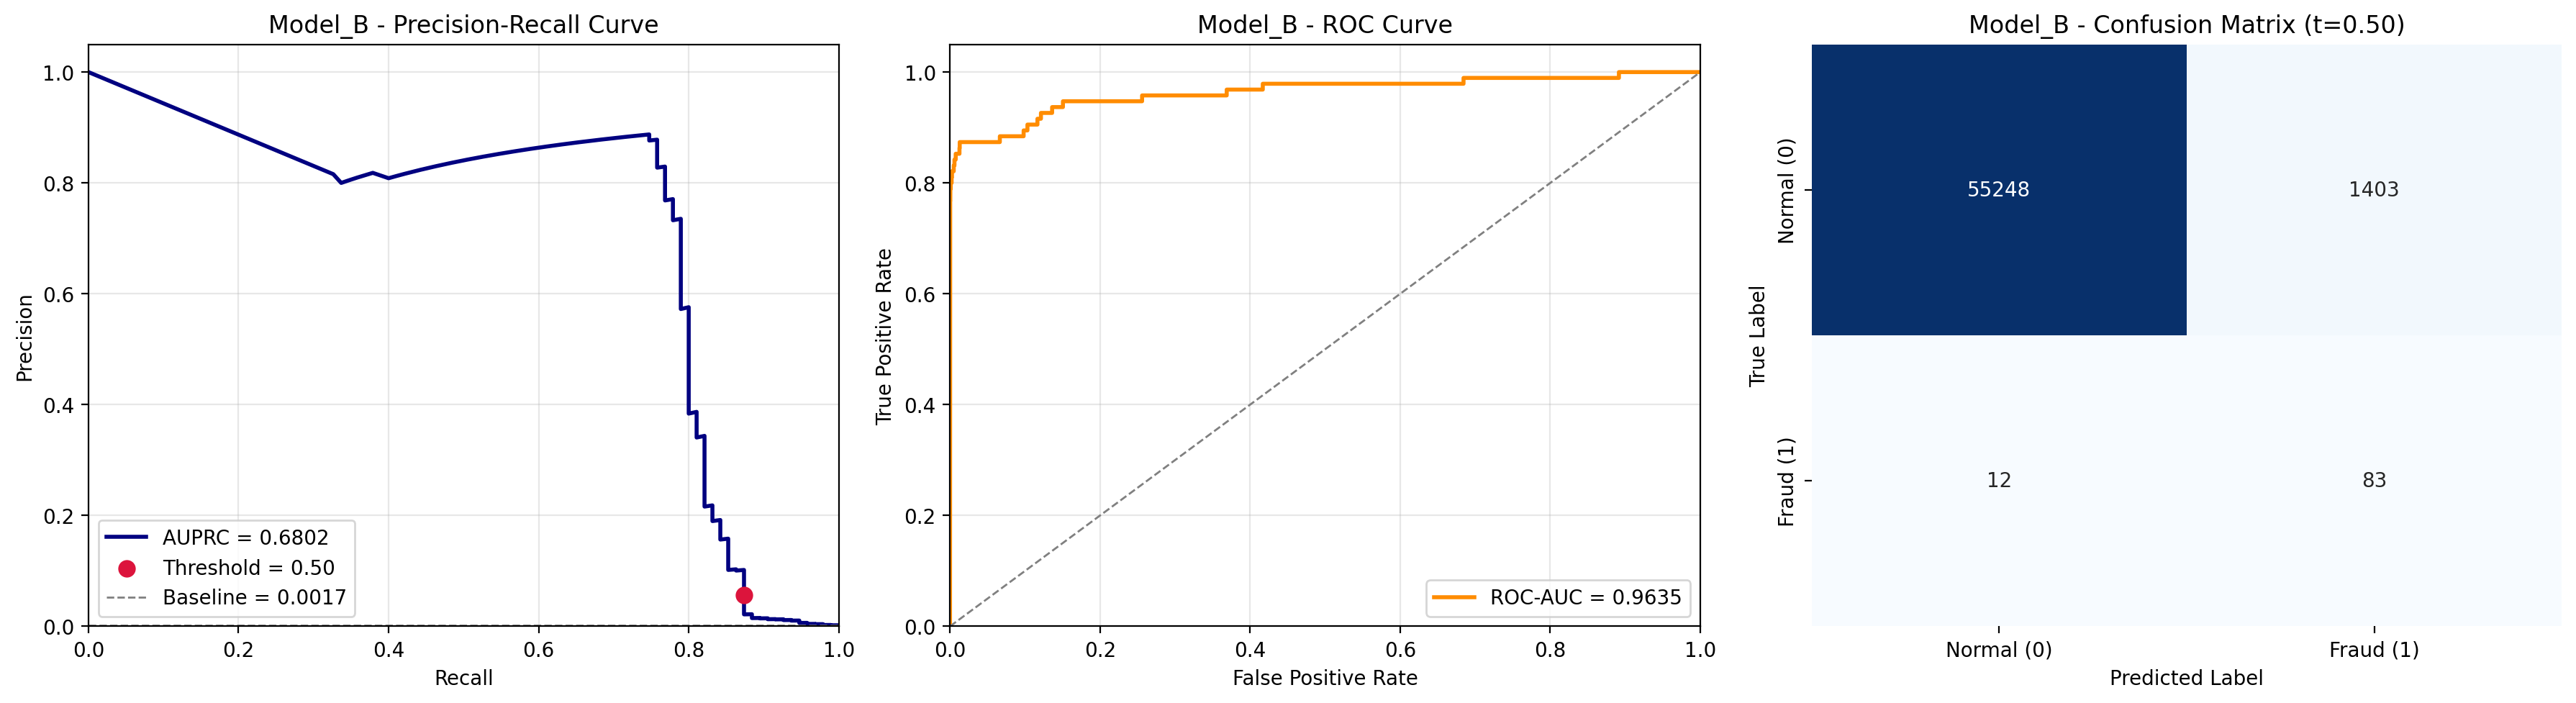

In [2]:
t0 = time.perf_counter()
lr_model, lr_test_metrics = run_model_b()
print(f"Elapsed (Model B - Logistic Regression): {time.perf_counter() - t0:.2f}s")
display(Image(filename=str(FIGURE_DIR / "model_b_evaluation.png")))

Fold 1 -> {'AUPRC': 0.7206, 'ROC_AUC': 0.9685, 'Precision': 0.7349, 'Recall': 0.8133, 'F1': 0.7722, 'MCC': 0.7728, 'Balanced_Accuracy': 0.9064, 'TP': 61, 'FP': 22, 'FN': 14, 'TN': 45299}


Fold 2 -> {'AUPRC': 0.7287, 'ROC_AUC': 0.974, 'Precision': 0.4924, 'Recall': 0.8667, 'F1': 0.628, 'MCC': 0.6526, 'Balanced_Accuracy': 0.9326, 'TP': 65, 'FP': 67, 'FN': 10, 'TN': 45254}


Fold 3 -> {'AUPRC': 0.6721, 'ROC_AUC': 0.9635, 'Precision': 0.6222, 'Recall': 0.7368, 'F1': 0.6747, 'MCC': 0.6765, 'Balanced_Accuracy': 0.868, 'TP': 56, 'FP': 34, 'FN': 20, 'TN': 45286}


Fold 4 -> {'AUPRC': 0.8067, 'ROC_AUC': 0.9787, 'Precision': 0.66, 'Recall': 0.8684, 'F1': 0.75, 'MCC': 0.7566, 'Balanced_Accuracy': 0.9338, 'TP': 66, 'FP': 34, 'FN': 10, 'TN': 45286}


Fold 5 -> {'AUPRC': 0.7385, 'ROC_AUC': 0.972, 'Precision': 0.64, 'Recall': 0.8421, 'F1': 0.7273, 'MCC': 0.7336, 'Balanced_Accuracy': 0.9207, 'TP': 64, 'FP': 36, 'FN': 12, 'TN': 45284}


TEST RESULT (MODEL B_2 - SVM): {'AUPRC': 0.7194, 'ROC_AUC': 0.9627, 'Precision': 0.7449, 'Recall': 0.7684, 'F1': 0.7565, 'MCC': 0.7562, 'Balanced_Accuracy': 0.884, 'TP': 73, 'FP': 25, 'FN': 22, 'TN': 56626}


Saved evaluation figure to: D:\DAI_HOC\Uni3\Machine learning\ml-project\outputs\figures\model_b_2_evaluation.png
Elapsed (Model B_2 - RBF SVM): 23.13s


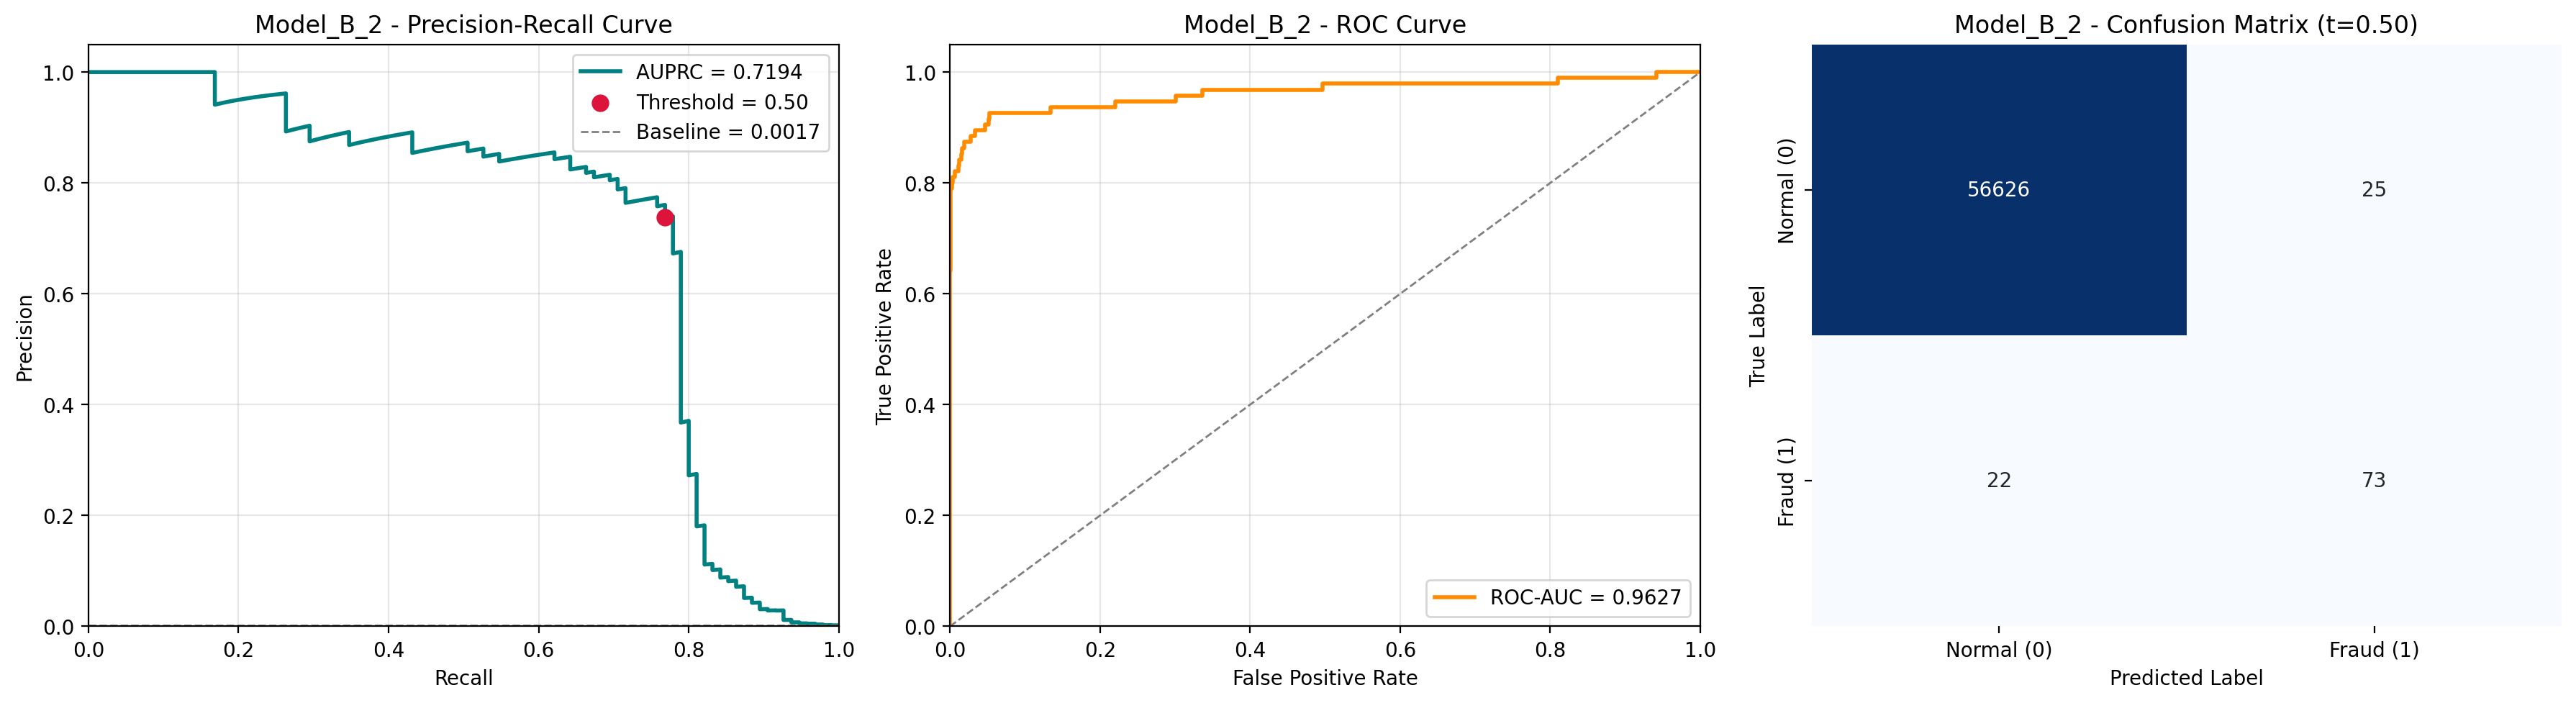

In [3]:
t0 = time.perf_counter()
svm_model, svm_test_metrics = run_model_b_2()
print(f"Elapsed (Model B_2 - RBF SVM): {time.perf_counter() - t0:.2f}s")
display(Image(filename=str(FIGURE_DIR / "model_b_2_evaluation.png")))

## 2. Chuẩn bị 3 biến thể đặc trưng thời gian

In [4]:
def load_and_clean_data_no_hour(file_path):
    df = pd.read_csv(file_path)
    df = df.drop_duplicates(keep="first").copy()
    df["Hour"] = (df["Time"] // 3600) % 24
    df["Log_Amount"] = np.log1p(df["Amount"])
    df = df.drop(columns=["Time", "Hour", "Amount"])
    return df


def load_and_clean_data_hour(file_path):
    df = pd.read_csv(file_path)
    df = df.drop_duplicates(keep="first").copy()
    df["Hour"] = (df["Time"] // 3600) % 24
    df["Log_Amount"] = np.log1p(df["Amount"])
    df = df.drop(columns=["Time", "Amount"])
    return df


data_no_hour = load_and_clean_data_no_hour(RAW_DATA_PATH)
data_sincos = load_and_clean_data(RAW_DATA_PATH)
data_hour = load_and_clean_data_hour(RAW_DATA_PATH)

for name, d in [("no_hour", data_no_hour), ("sincos", data_sincos), ("hour", data_hour)]:
    print(f"{name:8s} -> shape={d.shape}, n_features={d.shape[1] - 1}")

no_hour  -> shape=(283726, 30), n_features=29
sincos   -> shape=(283726, 32), n_features=31
hour     -> shape=(283726, 31), n_features=30


In [5]:
def find_best_f1_threshold(y_true, y_prob):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
    p = precisions[:-1]
    r = recalls[:-1]
    denom = p + r
    f1_scores = np.where(denom > 0, 2 * p * r / denom, 0.0)
    best_idx = int(np.argmax(f1_scores))
    return float(thresholds[best_idx]), float(f1_scores[best_idx])


def evaluate_variant(
    data,
    variant_name,
    model_name,
    build_model_fn,
    handle_imbalance_fn,
    evaluate_fn,
):
    t0 = time.perf_counter()
    X_train_full, X_test, y_train_full, y_test = split_train_test(
        data, test_size=TEST_SIZE, random_state=RANDOM_STATE
    )
    skf = get_cv_splitter()

    cv_metrics_list = []
    oof_probs = np.zeros(len(X_train_full), dtype=float)

    for train_idx, val_idx in skf.split(X_train_full, y_train_full):
        X_train = X_train_full.iloc[train_idx].copy()
        y_train = y_train_full.iloc[train_idx].copy()
        X_val = X_train_full.iloc[val_idx].copy()
        y_val = y_train_full.iloc[val_idx].copy()

        scaler = RobustScaler()
        X_train[COLS_TO_SCALE] = scaler.fit_transform(X_train[COLS_TO_SCALE])
        X_val[COLS_TO_SCALE] = scaler.transform(X_val[COLS_TO_SCALE])

        X_train_res, y_train_res = handle_imbalance_fn(X_train, y_train)
        model = build_model_fn()
        model.fit(X_train_res, y_train_res)

        y_val_prob = model.predict_proba(X_val)[:, 1]
        oof_probs[val_idx] = y_val_prob
        cv_metrics_list.append(evaluate_fn(y_val, y_val_prob, threshold=0.5))

    cv_mean_auprc = round(float(np.mean([m["AUPRC"] for m in cv_metrics_list])), 4)
    cv_mean_roc = round(float(np.mean([m["ROC_AUC"] for m in cv_metrics_list])), 4)
    cv_mean_f1 = round(float(np.mean([m["F1"] for m in cv_metrics_list])), 4)

    best_threshold, best_oof_f1 = find_best_f1_threshold(y_train_full, oof_probs)

    final_scaler = RobustScaler()
    X_train_scaled = X_train_full.copy()
    X_test_scaled = X_test.copy()
    X_train_scaled[COLS_TO_SCALE] = final_scaler.fit_transform(X_train_scaled[COLS_TO_SCALE])
    X_test_scaled[COLS_TO_SCALE] = final_scaler.transform(X_test_scaled[COLS_TO_SCALE])

    X_train_res, y_train_res = handle_imbalance_fn(X_train_scaled, y_train_full)
    final_model = build_model_fn()
    final_model.fit(X_train_res, y_train_res)

    y_test_prob = final_model.predict_proba(X_test_scaled)[:, 1]
    elapsed = round(time.perf_counter() - t0, 2)

    test_default = evaluate_fn(y_test, y_test_prob, threshold=0.5)
    test_tuned = evaluate_fn(y_test, y_test_prob, threshold=best_threshold)

    print(
        f"[{model_name} | {variant_name}] time={elapsed:.2f}s | "
        f"CV Mean(t=0.50): AUPRC={cv_mean_auprc:.4f}, ROC={cv_mean_roc:.4f}, F1={cv_mean_f1:.4f} | "
        f"OOF best_t={best_threshold:.6f} (OOF_F1={best_oof_f1:.4f})"
    )
    print(f"  Test (t=0.500000)         -> {test_default}")
    print(f"  Test (t={best_threshold:.6f}) -> {test_tuned}")

    rows = []
    for mode, th, res in [
        ("t=0.50", 0.5, test_default),
        ("OOF tuned", round(best_threshold, 6), test_tuned),
    ]:
        rows.append(
            {
                "Model": model_name,
                "Variant": variant_name,
                "Threshold_Mode": mode,
                "Threshold": th,
                "CV_AUPRC": cv_mean_auprc,
                **res,
                "Time_s": elapsed,
            }
        )
    return rows

## 3. Thử nghiệm Logistic Regression (Model B) trên 3 biến thể dữ liệu

In [6]:
lr_rows = []
for vname, vdata in [("no_hour", data_no_hour), ("sincos", data_sincos), ("hour", data_hour)]:
    lr_rows.extend(
        evaluate_variant(
            vdata,
            variant_name=vname,
            model_name="Logistic Regression",
            build_model_fn=build_lr_model,
            handle_imbalance_fn=handle_imbalance_lr,
            evaluate_fn=eval_lr,
        )
    )

[Logistic Regression | no_hour] time=3.80s | CV Mean(t=0.50): AUPRC=0.7383, ROC=0.9812, F1=0.1084 | OOF best_t=1.000000 (OOF_F1=0.8128)
  Test (t=0.500000)         -> {'AUPRC': 0.677, 'ROC_AUC': 0.9616, 'Precision': 0.055, 'Recall': 0.8737, 'F1': 0.1036, 'MCC': 0.2157, 'Balanced_Accuracy': 0.9243, 'TP': 83, 'FP': 1425, 'FN': 12, 'TN': 55226}
  Test (t=1.000000) -> {'AUPRC': 0.677, 'ROC_AUC': 0.9616, 'Precision': 0.8765, 'Recall': 0.7474, 'F1': 0.8068, 'MCC': 0.8091, 'Balanced_Accuracy': 0.8736, 'TP': 71, 'FP': 10, 'FN': 24, 'TN': 56641}


[Logistic Regression | sincos] time=4.53s | CV Mean(t=0.50): AUPRC=0.7402, ROC=0.9794, F1=0.1078 | OOF best_t=0.999999 (OOF_F1=0.8121)
  Test (t=0.500000)         -> {'AUPRC': 0.6802, 'ROC_AUC': 0.9635, 'Precision': 0.0559, 'Recall': 0.8737, 'F1': 0.105, 'MCC': 0.2173, 'Balanced_Accuracy': 0.9245, 'TP': 83, 'FP': 1403, 'FN': 12, 'TN': 55248}
  Test (t=0.999999) -> {'AUPRC': 0.6802, 'ROC_AUC': 0.9635, 'Precision': 0.878, 'Recall': 0.7579, 'F1': 0.8136, 'MCC': 0.8155, 'Balanced_Accuracy': 0.8789, 'TP': 72, 'FP': 10, 'FN': 23, 'TN': 56641}


[Logistic Regression | hour] time=8.92s | CV Mean(t=0.50): AUPRC=0.7406, ROC=0.9812, F1=0.1063 | OOF best_t=0.999999 (OOF_F1=0.8132)
  Test (t=0.500000)         -> {'AUPRC': 0.6793, 'ROC_AUC': 0.9622, 'Precision': 0.0549, 'Recall': 0.8737, 'F1': 0.1032, 'MCC': 0.2153, 'Balanced_Accuracy': 0.9242, 'TP': 83, 'FP': 1430, 'FN': 12, 'TN': 55221}
  Test (t=0.999999) -> {'AUPRC': 0.6793, 'ROC_AUC': 0.9622, 'Precision': 0.878, 'Recall': 0.7579, 'F1': 0.8136, 'MCC': 0.8155, 'Balanced_Accuracy': 0.8789, 'TP': 72, 'FP': 10, 'FN': 23, 'TN': 56641}


## 4. Thử nghiệm Kernel SVM - RBF (Model B_2) trên 3 biến thể dữ liệu

In [7]:
svm_rows = []
for vname, vdata in [("no_hour", data_no_hour), ("sincos", data_sincos), ("hour", data_hour)]:
    svm_rows.extend(
        evaluate_variant(
            vdata,
            variant_name=vname,
            model_name="SVM (RBF)",
            build_model_fn=build_svm_model,
            handle_imbalance_fn=handle_imbalance_svm,
            evaluate_fn=eval_svm,
        )
    )

[SVM (RBF) | no_hour] time=18.26s | CV Mean(t=0.50): AUPRC=0.7215, ROC=0.9714, F1=0.7047 | OOF best_t=0.908722 (OOF_F1=0.7692)
  Test (t=0.500000)         -> {'AUPRC': 0.7222, 'ROC_AUC': 0.9604, 'Precision': 0.7157, 'Recall': 0.7684, 'F1': 0.7411, 'MCC': 0.7411, 'Balanced_Accuracy': 0.884, 'TP': 73, 'FP': 29, 'FN': 22, 'TN': 56622}
  Test (t=0.908722) -> {'AUPRC': 0.7222, 'ROC_AUC': 0.9604, 'Precision': 0.7952, 'Recall': 0.6947, 'F1': 0.7416, 'MCC': 0.7429, 'Balanced_Accuracy': 0.8472, 'TP': 66, 'FP': 17, 'FN': 29, 'TN': 56634}


[SVM (RBF) | sincos] time=18.27s | CV Mean(t=0.50): AUPRC=0.7333, ROC=0.9713, F1=0.7104 | OOF best_t=0.915602 (OOF_F1=0.7656)
  Test (t=0.500000)         -> {'AUPRC': 0.7194, 'ROC_AUC': 0.9627, 'Precision': 0.7449, 'Recall': 0.7684, 'F1': 0.7565, 'MCC': 0.7562, 'Balanced_Accuracy': 0.884, 'TP': 73, 'FP': 25, 'FN': 22, 'TN': 56626}
  Test (t=0.915602) -> {'AUPRC': 0.7194, 'ROC_AUC': 0.9627, 'Precision': 0.8049, 'Recall': 0.6947, 'F1': 0.7458, 'MCC': 0.7474, 'Balanced_Accuracy': 0.8472, 'TP': 66, 'FP': 16, 'FN': 29, 'TN': 56635}


[SVM (RBF) | hour] time=18.51s | CV Mean(t=0.50): AUPRC=0.7285, ROC=0.9719, F1=0.7150 | OOF best_t=0.915436 (OOF_F1=0.7717)
  Test (t=0.500000)         -> {'AUPRC': 0.7182, 'ROC_AUC': 0.9602, 'Precision': 0.73, 'Recall': 0.7684, 'F1': 0.7487, 'MCC': 0.7485, 'Balanced_Accuracy': 0.884, 'TP': 73, 'FP': 27, 'FN': 22, 'TN': 56624}
  Test (t=0.915436) -> {'AUPRC': 0.7182, 'ROC_AUC': 0.9602, 'Precision': 0.8049, 'Recall': 0.6947, 'F1': 0.7458, 'MCC': 0.7474, 'Balanced_Accuracy': 0.8472, 'TP': 66, 'FP': 16, 'FN': 29, 'TN': 56635}


## 5. Bảng tổng hợp và biểu đồ so sánh Logistic Regression vs. SVM

,Model,Variant,Threshold_Mode,Threshold,CV_AUPRC,AUPRC,ROC_AUC,Precision,Recall,F1,MCC,Balanced_Accuracy,TP,FP,FN,TN,Time_s
0,Logistic Regression,no_hour,t=0.50,0.500000,0.7383,0.6770,0.9616,0.0550,0.8737,0.1036,0.2157,0.9243,83,1425,12,55226,3.80
1,Logistic Regression,no_hour,OOF tuned,1.000000,0.7383,0.6770,0.9616,0.8765,0.7474,0.8068,0.8091,0.8736,71,10,24,56641,3.80
2,Logistic Regression,sincos,t=0.50,0.500000,0.7402,0.6802,0.9635,0.0559,0.8737,0.1050,0.2173,0.9245,83,1403,12,55248,4.53
3,Logistic Regression,sincos,OOF tuned,0.999999,0.7402,0.6802,0.9635,0.8780,0.7579,0.8136,0.8155,0.8789,72,10,23,56641,4.53
4,Logistic Regression,hour,t=0.50,0.500000,0.7406,0.6793,0.9622,0.0549,0.8737,0.1032,0.2153,0.9242,83,1430,12,55221,8.92
5,Logistic Regression,hour,OOF tuned,0.999999,0.7406,0.6793,0.9622,0.8780,0.7579,0.8136,0.8155,0.8789,72,10,23,56641,8.92
6,SVM (RBF),no_hour,t=0.50,0.500000,0.7215,0.7222,0.9604,0.7157,0.7684,0.7411,0.7411,0.8840,73,29,22,56622,18.26
7,SVM (RBF),no_hour,OOF tuned,0.908722,0.7215,0.7222,0.9604,0.7952,0.6947,0.7416,0.7429,0.8472,66,17,29,56634,18.26
8,SVM (RBF),sincos,t=0.50,0.500000,0.7333,0.7194,0.9627,0.7449,0.7684,0.7565,0.7562,0.8840,73,25,22,56626,18.27
9,SVM (RBF),sincos,OOF tuned,0.915602,0.7333,0.7194,0.9627,0.8049,0.6947,0.7458,0.7474,0.8472,66,16,29,56635,18.27


Saved comparison chart to: D:\DAI_HOC\Uni3\Machine learning\ml-project\outputs\figures\logistic_vs_svm_comparison.png


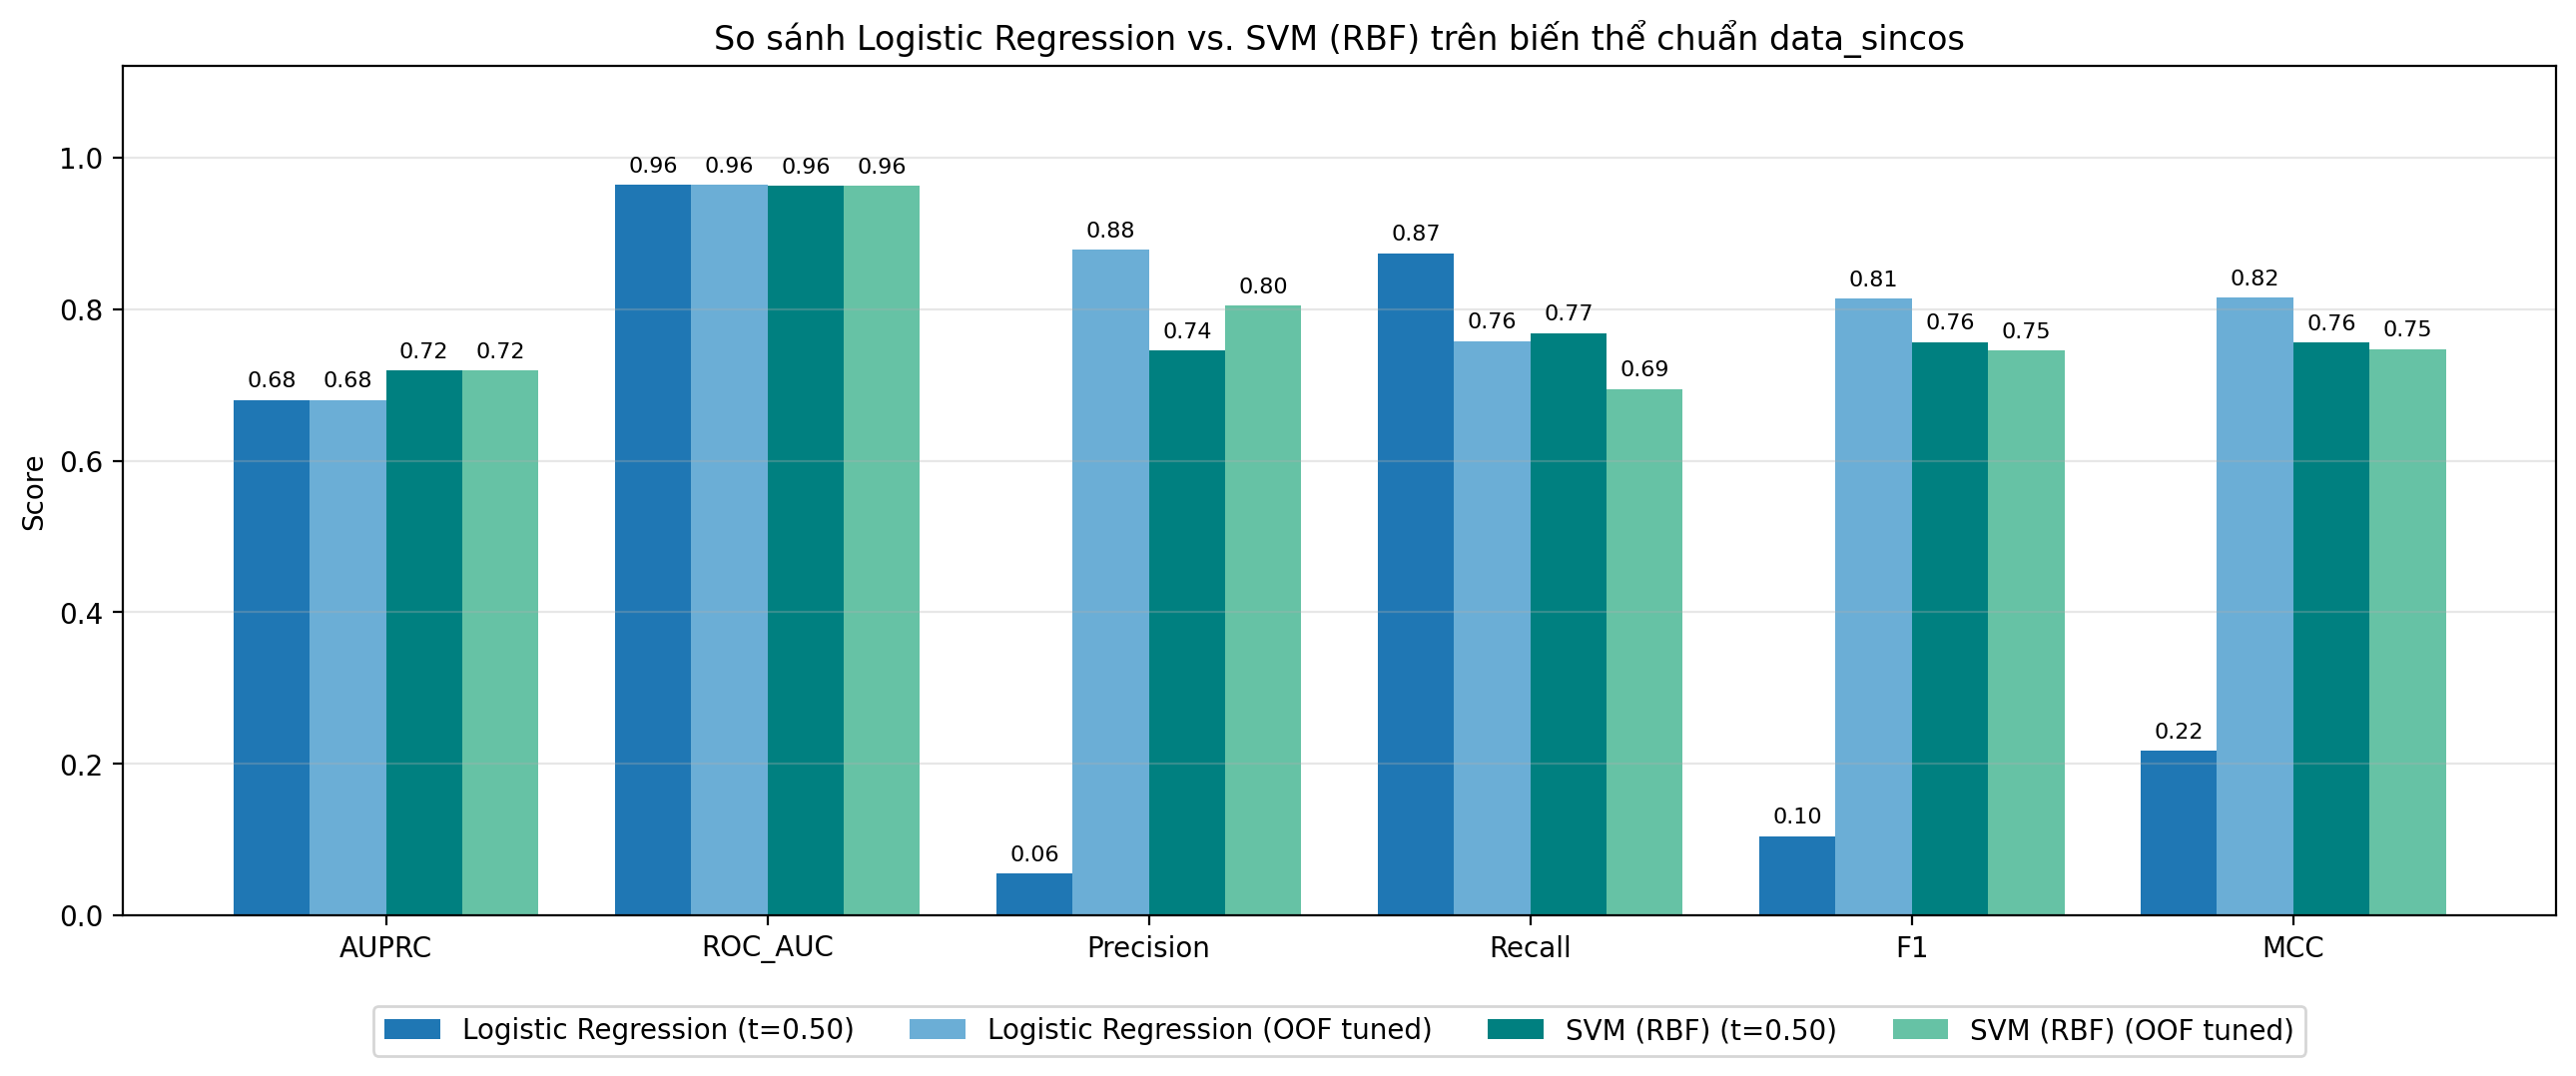

In [8]:
cols_order = [
    "Model",
    "Variant",
    "Threshold_Mode",
    "Threshold",
    "CV_AUPRC",
    "AUPRC",
    "ROC_AUC",
    "Precision",
    "Recall",
    "F1",
    "MCC",
    "Balanced_Accuracy",
    "TP",
    "FP",
    "FN",
    "TN",
    "Time_s",
]
summary_df = pd.DataFrame(lr_rows + svm_rows)[cols_order]
display(summary_df)

sincos_df = summary_df[summary_df["Variant"] == "sincos"].copy()
sincos_df["Label"] = sincos_df["Model"] + " (" + sincos_df["Threshold_Mode"] + ")"

metrics_to_plot = ["AUPRC", "ROC_AUC", "Precision", "Recall", "F1", "MCC"]
x = np.arange(len(metrics_to_plot))
width = 0.2

fig, ax = plt.subplots(figsize=(13, 5.5))
colors = ["#1f77b4", "#6baed6", "#008080", "#66c2a5"]

for i, (_, row) in enumerate(sincos_df.iterrows()):
    vals = [row[m] for m in metrics_to_plot]
    offset = (i - (len(sincos_df) - 1) / 2) * width
    bars = ax.bar(x + offset, vals, width, label=row["Label"], color=colors[i % len(colors)])
    for bar in bars:
        h = bar.get_height()
        ax.annotate(
            f"{h:.2f}",
            xy=(bar.get_x() + bar.get_width() / 2, h),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
        )

ax.set_title("So sánh Logistic Regression vs. SVM (RBF) trên biến thể chuẩn data_sincos")
ax.set_xticks(x)
ax.set_xticklabels(metrics_to_plot)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=4, frameon=True)

plt.tight_layout()
os.makedirs(FIGURE_DIR, exist_ok=True)
comp_path = FIGURE_DIR / "logistic_vs_svm_comparison.png"
plt.savefig(comp_path, dpi=200, bbox_inches="tight")
plt.close(fig)
print("Saved comparison chart to:", comp_path)
display(Image(filename=str(comp_path)))